# IF25-40305: Sistem Teknologi Multimedia (STM)
## Modul 10 — Video Digital & Motion Estimation: Frame, Codec, Optical Flow, Green Screen & Tracking

**Institut Teknologi Sumatera (ITERA) — Program Studi Informatika**
*Materi Kuliah & Hands-on Lab Semester Ganjil 2026/2027 · Pertemuan 10*

---

### 🎯 Capaian Pembelajaran Modul 10:
1. Memahami video sebagai **tumpukan frame**: FPS, resolusi, durasi.
2. **Membaca** dan **menulis** video dengan `cv2.VideoCapture` dan `cv2.VideoWriter` (termasuk webcam).
3. Memahami kenapa file video bisa **ratusan kali lebih kecil** dari versi mentahnya (ide **codec** dan I/P/B-frame).
4. Mencari **ke mana piksel berpindah**: block matching dan optical flow (**Lucas-Kanade** & Farnebäck).
5. Membuat efek **green screen** (chroma key) dengan HSV + morfologi.
6. **Melacak objek** dengan tracker CSRT dan KCF, termasuk mengenali kapan tracker gagal.
7. Menggabungkan green screen + tracking, lalu menjalankan demo **hidung badut** dengan webcam.

### 🧭 Cara Memakai Notebook Ini
- Di kelas, dosen menjalankan bagian bertanda **🎬 Demo Dosen** di proyektor. Anda cukup memperhatikan dan menebak.
- Di rumah, jalankan notebook dari atas ke bawah. Sel bertanda **✏️ Coba Ubah** berisi angka yang boleh Anda ganti.
- Tidak ada challenge yang dinilai di notebook ini. Santai saja, dan banyak-banyak mencoba!
- Bagian 9 memakai script terpisah **`10_hidung_badut.py`** yang butuh webcam, jadi dijalankan di laptop Anda (bukan di Colab).

> 📎 Slide pendamping: *Pertemuan 10 — Video Digital & Motion Estimation* (mctm.web.id/stm). Angka di slide dihitung dari video dan kode yang sama dengan notebook ini.

## 1. Persiapan

Modul ini memakai **`opencv-contrib-python`** (OpenCV + modul tambahan), **`numpy`**, **`matplotlib`**, dan **`pillow`**.

> ⚠️ **Tentang paket OpenCV.** Tracker **CSRT** dan **KCF** hanya ada di paket *contrib*. Kalau sel di bawah melaporkan CSRT/KCF tidak tersedia, jalankan di terminal:
> ```
> pip uninstall -y opencv-python opencv-python-headless
> pip install opencv-contrib-python
> ```
> Tanpa itu notebook tetap jalan, tetapi tracker diganti **MIL** sebagai cadangan (hasilnya bisa berbeda dari slide).

Video contoh ada di folder `video/`:
- `bola_green_screen.mp4` — bola pantai memantul di depan layar hijau (sintetis buatan pengampu, CC0);
- `pejalan_kaki.mp4` — 15 detik pertama `vtest.avi` dari sampel OpenCV (Apache-2.0), diperkecil ke 640×480.

Latar pengganti: `image/latar_pantai.jpg` (sintetis, CC0).

In [1]:
import os
import time
import numpy as np
import cv2
import matplotlib.pyplot as plt
from PIL import Image as PILImage
from IPython.display import Image, display

plt.rcParams['font.family'] = 'sans-serif'
plt.rcParams['figure.dpi'] = 100
plt.rcParams['axes.grid'] = False
%config InlineBackend.figure_formats = ['jpeg']
%config InlineBackend.print_figure_kwargs = {'bbox_inches': 'tight', 'pil_kwargs': {'quality': 85}}

os.makedirs("output", exist_ok=True)
print(f"OpenCV : {cv2.__version__}")
print(f"NumPy  : {np.__version__}")
for nama in ["TrackerCSRT_create", "TrackerKCF_create"]:
    ada = hasattr(cv2, nama)
    print(f"{nama:20s}: {'tersedia ✅' if ada else 'TIDAK ADA ❌ (pasang opencv-contrib-python)'}")

OpenCV : 5.0.0
NumPy  : 2.5.4
TrackerCSRT_create  : tersedia ✅
TrackerKCF_create   : tersedia ✅


In [2]:
# ---------- Fungsi bantu tampilan ----------
def cari_file(nama):
    # notebook bisa dijalankan dari root repo atau dari folder notebook_handson
    for p in [nama, f"notebook_handson/{nama}", f"../{nama}"]:
        if os.path.exists(p):
            return p
    raise FileNotFoundError(f"Berkas tidak ditemukan: {nama}")


def tampil(ax, img, judul=None):
    if img.ndim == 2:
        ax.imshow(img, cmap='gray', vmin=0, vmax=255, interpolation='nearest')
    else:
        ax.imshow(cv2.cvtColor(img, cv2.COLOR_BGR2RGB), interpolation='nearest')
    ax.set_xticks([]); ax.set_yticks([])
    if judul:
        ax.set_title(judul, fontsize=11, fontweight='bold')


def jajar(daftar, ukuran=4):
    # daftar = [(img, judul), ...] -> ditampilkan berdampingan
    fig, axes = plt.subplots(1, len(daftar), figsize=(ukuran * len(daftar), ukuran * 0.65))
    for ax, (im, judul) in zip(np.atleast_1d(axes), daftar):
        tampil(ax, im, judul)
    plt.tight_layout(); plt.show()


def tampil_gif(frames, nama, fps=30, lebar=320, langkah=3):
    # Simpan list frame (BGR) menjadi GIF animasi, lalu tampilkan di notebook
    tinggi = int(frames[0].shape[0] * lebar / frames[0].shape[1])
    gambar = [PILImage.fromarray(cv2.cvtColor(cv2.resize(f, (lebar, tinggi)), cv2.COLOR_BGR2RGB))
              for f in frames[::langkah]]
    path = os.path.join("output", nama)
    gambar[0].save(path, save_all=True, append_images=gambar[1:], duration=int(1000 * langkah / fps), loop=0)
    with open(path, "rb") as fh:
        display(Image(data=fh.read(), format="gif"))
    print(f"GIF disimpan: {path} ({os.path.getsize(path) / 1024:.0f} KB)")


def tulis(img, teks, xy, skala=0.7, warna=(255, 255, 255)):
    # teks dengan garis tepi hitam agar terbaca di latar apa pun
    cv2.putText(img, teks, xy, cv2.FONT_HERSHEY_SIMPLEX, skala, (0, 0, 0), 5, cv2.LINE_AA)
    cv2.putText(img, teks, xy, cv2.FONT_HERSHEY_SIMPLEX, skala, warna, 2, cv2.LINE_AA)

## 2. Video = Tumpukan Foto

Video hanyalah **banyak citra** (disebut **frame**) yang ditampilkan bergantian dengan cepat, seperti **flipbook**.
Kita buka video dengan `cv2.VideoCapture`, lalu ambil frame satu per satu dengan `cap.read()` sampai habis.

`cap.read()` memberi **dua** nilai:
- `ok` → `True` kalau berhasil, `False` kalau video sudah habis;
- `frame` → citra BGR biasa (array NumPy), persis seperti di Modul 06.

In [3]:
def baca_video(path):
    # Membaca SELURUH frame video ke dalam list. Mengembalikan (frames, fps).
    cap = cv2.VideoCapture(cari_file(path))
    fps = cap.get(cv2.CAP_PROP_FPS)
    frames = []
    while True:
        ok, frame = cap.read()     # ambil 1 frame
        if not ok:                 # video sudah habis -> berhenti
            break
        frames.append(frame)
    cap.release()                  # tutup "pemutar video"
    return frames, fps


bola, fps_bola = baca_video("video/bola_green_screen.mp4")
jalan, fps_jalan = baca_video("video/pejalan_kaki.mp4")

for nama, frames, fps in [("bola_green_screen", bola, fps_bola), ("pejalan_kaki", jalan, fps_jalan)]:
    h, w = frames[0].shape[:2]
    print(f"{nama:18s}: {w}x{h} piksel, {fps:.0f} fps, {len(frames)} frame, durasi {len(frames) / fps:.1f} detik")
print("satu frame bola:", bola[0].shape, bola[0].dtype)

bola_green_screen : 640x360 piksel, 30 fps, 120 frame, durasi 4.0 detik
pejalan_kaki      : 640x480 piksel, 10 fps, 150 frame, durasi 15.0 detik
satu frame bola: (360, 640, 3) uint8


Satu frame berukuran `(360, 640, 3)` = tinggi × lebar × warna. Seluruh video bola = **120** frame seperti itu.
Mari kita tampilkan beberapa frame berjajar seperti halaman flipbook.

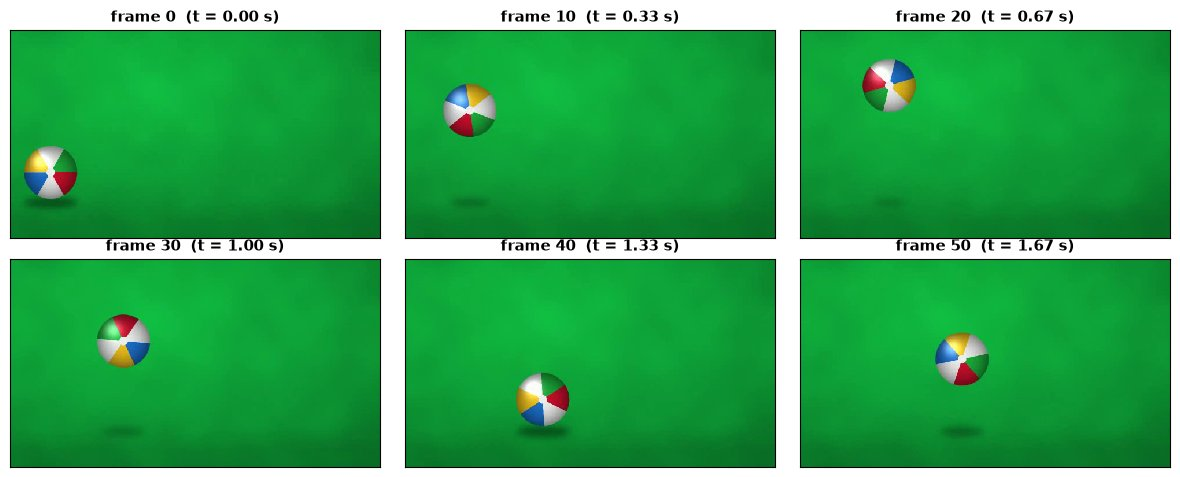

In [4]:
# ✏️ Coba Ubah: frame mana saja yang ingin ditampilkan?
PILIH = [0, 10, 20, 30, 40, 50]

fig, axes = plt.subplots(2, 3, figsize=(12, 4.8))
for ax, i in zip(axes.ravel(), PILIH):
    tampil(ax, bola[i], f"frame {i}  (t = {i / fps_bola:.2f} s)")
plt.tight_layout(); plt.show()

### 2.1 FPS: berapa gambar per detik?

**FPS** (*frames per second*) = berapa frame ditampilkan dalam satu detik. Video bola kita 30 fps.
Bagaimana kalau kita hanya mengambil sebagian frame? Sel di bawah menumpuk posisi bola selama **1 detik pertama**
dengan tiga "kecepatan rekam" berbeda. Untuk mengambil bolanya saja, kita pinjam fungsi `mask_objek` dari Bagian 6
(sementara anggap saja ia "memotong" bola dari latar hijau).

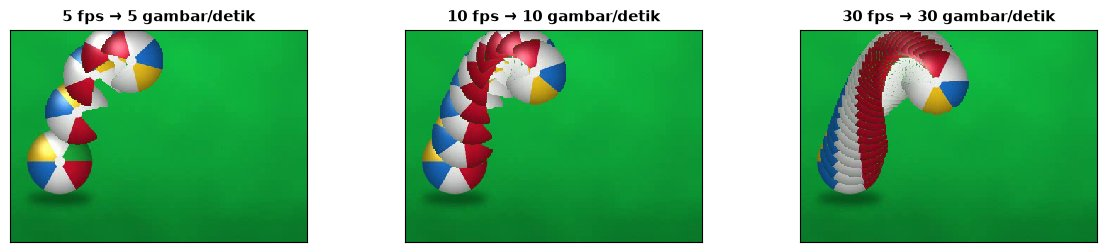

In [5]:
HIJAU_BAWAH = (35, 60, 60)     # batas bawah HSV warna "hijau layar"
HIJAU_ATAS = (85, 255, 255)    # batas atas


def mask_objek(frame, bawah=HIJAU_BAWAH, atas=HIJAU_ATAS, k=5):
    # 255 = objek (bukan hijau), 0 = layar hijau. Penjelasan lengkap di Bagian 6.
    hsv = cv2.cvtColor(frame, cv2.COLOR_BGR2HSV)
    hijau = cv2.inRange(hsv, np.array(bawah), np.array(atas))
    objek = cv2.bitwise_not(hijau)
    kernel = np.ones((k, k), np.uint8)
    objek = cv2.morphologyEx(objek, cv2.MORPH_OPEN, kernel)    # buang bintik noise
    objek = cv2.morphologyEx(objek, cv2.MORPH_CLOSE, kernel)   # tambal lubang kecil
    return objek


def tumpuk_bola(langkah, n=30):
    # tempel bola dari setiap 'langkah' frame (selama n frame pertama) ke atas frame 0
    hasil = bola[0].copy()
    for i in range(0, n, langkah):
        m = mask_objek(bola[i]) > 0
        hasil[m] = bola[i][m]
    return hasil


# ✏️ Coba Ubah: tambahkan fps lain, misalnya 2 atau 15
jajar([(tumpuk_bola(30 // f)[60:, :420], f"{f} fps → {len(range(0, 30, 30 // f))} gambar/detik")
       for f in [5, 10, 30]])

Pada **5 fps**, bola "meloncat-loncat" dengan jarak lebar. Pada **30 fps** langkahnya rapat sehingga terlihat mulus.
Itulah kenapa video 5 fps terasa patah-patah.

> 💡 **Jumlah frame = FPS × durasi.** Slow-motion HP: rekam 240 fps selama 1 detik, putar di 30 fps → tampil 8 detik.

## 3. Membaca & Menulis Video

Pola dasar pengolahan video **selalu sama**:

```
buka  →  [ ambil 1 frame  →  olah  →  tampilkan / simpan ]  diulang sampai habis  →  tutup
```

Untuk **menyimpan** hasil olahan, kita pakai `cv2.VideoWriter`. Ia butuh empat hal:
1. nama file, 2. jenis codec (`fourcc`), 3. FPS, 4. ukuran frame sebagai **(lebar, tinggi)**.

> ⚠️ **Jebakan klasik:** ukuran di `VideoWriter` harus **sama persis** dengan ukuran frame yang ditulis.
> Kalau berbeda, OpenCV **tidak memberi error**, tetapi file hasilnya kosong.

In [6]:
# Tulis ulang video bola: grayscale + nomor frame di pojok
h, w = bola[0].shape[:2]
fourcc = cv2.VideoWriter_fourcc(*"mp4v")
out = cv2.VideoWriter("output/bola_abu.mp4", fourcc, fps_bola, (w, h))   # (lebar, tinggi)!

for i, frame in enumerate(bola):
    abu = cv2.cvtColor(frame, cv2.COLOR_BGR2GRAY)
    abu = cv2.cvtColor(abu, cv2.COLOR_GRAY2BGR)       # tetap 3 kanal agar cocok dengan writer
    tulis(abu, f"frame {i}", (15, 35))
    out.write(abu)
out.release()                                          # WAJIB, agar file utuh

print("ukuran file benar :", os.path.getsize("output/bola_abu.mp4") // 1024, "KB")

# Bandingkan: ukuran writer SALAH
salah = cv2.VideoWriter("output/bola_salah.mp4", fourcc, fps_bola, (1280, 720))
for frame in bola:
    salah.write(frame)
salah.release()
print("ukuran file salah :", os.path.getsize("output/bola_salah.mp4") // 1024, "KB  ← frame-nya ditolak diam-diam!")

ukuran file benar : 239 KB
ukuran file salah : 0 KB  ← frame-nya ditolak diam-diam!


frame di bola_abu.mp4  : 120
frame di bola_salah.mp4: 0


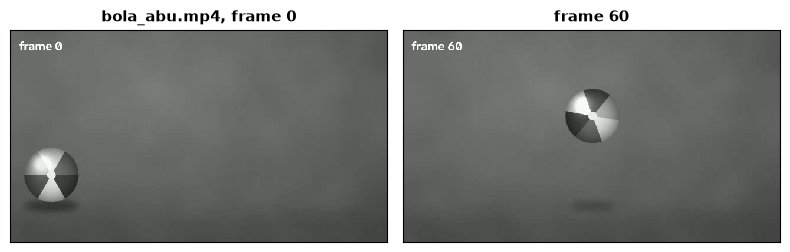

In [7]:
# Cek hasil: baca lagi video yang barusan ditulis
cek, _ = baca_video("output/bola_abu.mp4")
cek_salah, _ = baca_video("output/bola_salah.mp4")
print("frame di bola_abu.mp4  :", len(cek))
print("frame di bola_salah.mp4:", len(cek_salah))
jajar([(cek[0], "bola_abu.mp4, frame 0"), (cek[60], "frame 60")])

### 3.1 Webcam = angka 0

Untuk membaca **webcam**, cukup ganti nama file dengan angka: `cv2.VideoCapture(0)`.
Sisanya sama persis. Bedanya, webcam tidak pernah "habis", jadi kita yang menekan tombol untuk berhenti.

Sel di bawah **tidak dijalankan otomatis** (Colab dan server tidak punya webcam). Kalau Anda menjalankan notebook di laptop sendiri,
ubah `PAKAI_WEBCAM = True` untuk mencoba. Jendela akan muncul; tekan **q** untuk menutup.

In [8]:
PAKAI_WEBCAM = False   # ✏️ Coba Ubah: True kalau notebook berjalan di laptop yang punya webcam

if PAKAI_WEBCAM:
    cap = cv2.VideoCapture(0)               # 0 = kamera bawaan laptop
    while True:
        ok, frame = cap.read()
        if not ok:
            break
        frame = cv2.flip(frame, 1)           # efek cermin
        cv2.imshow("Webcam - tekan q untuk keluar", frame)
        if cv2.waitKey(1) & 0xFF == ord("q"):   # waitKey(1), BUKAN waitKey(0)
            break
    cap.release()
    cv2.destroyAllWindows()
else:
    print("Lewati demo webcam. Ubah PAKAI_WEBCAM = True di laptop sendiri untuk mencoba.")

Lewati demo webcam. Ubah PAKAI_WEBCAM = True di laptop sendiri untuk mencoba.


## 4. Rahasia Ukuran Video

Berapa besar video kita kalau **semua piksel** disimpan apa adanya (mentah)?
Satu piksel warna = 3 byte, jadi ukuran mentah = lebar × tinggi × 3 × jumlah frame.

In [9]:
for nama, frames in [("bola_green_screen", bola), ("pejalan_kaki", jalan)]:
    h, w = frames[0].shape[:2]
    mentah = w * h * 3 * len(frames) / 1e6
    mp4 = os.path.getsize(cari_file(f"video/{nama}.mp4")) / 1e6
    print(f"{nama:18s}: mentah {mentah:6.1f} MB | file MP4 {mp4:5.2f} MB | {mentah / mp4:4.0f}x lebih kecil")

menit = 1920 * 1080 * 3 * 30 * 60 / 1e9
print(f"\nVideo 1 menit Full HD 30 fps, mentah = {menit:.1f} GB")

bola_green_screen : mentah   82.9 MB | file MP4  0.31 MB |  264x lebih kecil
pejalan_kaki      : mentah  138.2 MB | file MP4  1.30 MB |  106x lebih kecil

Video 1 menit Full HD 30 fps, mentah = 11.2 GB


Kenapa file MP4 bisa **ratusan kali** lebih kecil? Mari lihat apa yang sebenarnya **berubah** dari satu frame ke frame berikutnya.

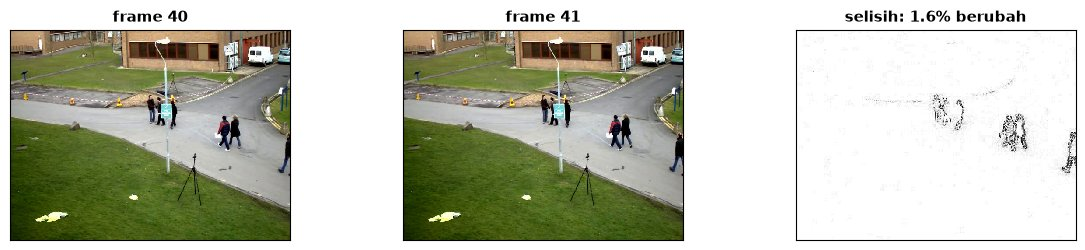

98.4% piksel praktis SAMA. Kenapa harus disimpan ulang?


In [10]:
# ✏️ Coba Ubah: bandingkan frame yang berjauhan, misalnya 40 dan 60
A, B = 40, 41

abu_a = cv2.cvtColor(jalan[A], cv2.COLOR_BGR2GRAY)
abu_b = cv2.cvtColor(jalan[B], cv2.COLOR_BGR2GRAY)
selisih = cv2.absdiff(abu_a, abu_b)
persen = (selisih > 15).mean() * 100

jajar([(jalan[A], f"frame {A}"), (jalan[B], f"frame {B}"),
       (255 - np.clip(selisih * 4, 0, 255).astype(np.uint8), f"selisih: {persen:.1f}% berubah")])
print(f"{100 - persen:.1f}% piksel praktis SAMA. Kenapa harus disimpan ulang?")

Inilah ide **codec** (coder–decoder) seperti H.264:
- **I-frame** (*intra*): foto lengkap, disimpan sesekali (misalnya tiap 1–2 detik).
- **P-frame** (*predicted*): hanya **catatan perubahan** dari frame sebelumnya: "kotak ini pindah ke sana".
- **B-frame** (*bi-directional*): boleh merujuk ke frame sebelum **dan** sesudahnya. Paling hemat.

Catatan "kotak ini pindah ke sana" didapat dari **motion estimation**, topik bagian berikutnya.

## 5. Ke Mana Piksel Pindah? (Motion Estimation)

### 5.1 Block matching: cari kotak yang paling mirip

1. Ambil satu kotak kecil (16×16) dari frame lama.
2. Cari di frame baru, tapi **hanya di sekitar** posisi lamanya (misalnya ±12 piksel).
3. Posisi dengan **selisih piksel paling kecil** = tujuan pindahnya.
4. Panah dari posisi lama ke posisi baru = **vektor gerak** (*motion vector*).

OpenCV punya `cv2.matchTemplate` yang menghitung "seberapa beda" kotak di setiap posisi sekaligus.

kotak di (556, 268) pindah dx = -10, dy = -5


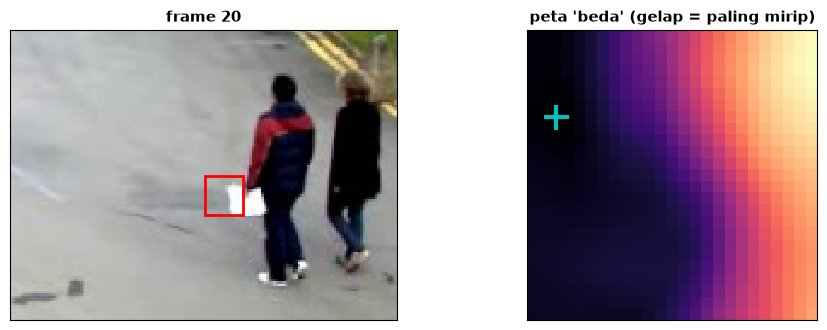

In [11]:
def cari_blok(a, b, x, y, blok=16, cari=12):
    # Cari kotak a[y:y+blok, x:x+blok] di frame b, dalam jendela ±cari piksel.
    ref = a[y:y + blok, x:x + blok]
    jendela = b[y - cari:y + blok + cari, x - cari:x + blok + cari]
    beda = cv2.matchTemplate(jendela, ref, cv2.TM_SQDIFF)   # makin kecil = makin mirip
    _, _, posisi, _ = cv2.minMaxLoc(beda)
    return posisi[0] - cari, posisi[1] - cari, beda


T0, K = 20, 2
ga = cv2.cvtColor(jalan[T0], cv2.COLOR_BGR2GRAY).astype(np.float32)
gb = cv2.cvtColor(jalan[T0 + K], cv2.COLOR_BGR2GRAY).astype(np.float32)

# ✏️ Coba Ubah: posisi kotak (x, y). (556, 268) ada di kantong kertas putih yang dibawa pejalan kaki.
x, y = 556, 268
dx, dy, beda = cari_blok(ga, gb, x, y)
print(f"kotak di ({x}, {y}) pindah dx = {dx}, dy = {dy}")

fig, axes = plt.subplots(1, 2, figsize=(10, 3.4))
tampil(axes[0], jalan[T0][y - 60:y + 60, x - 80:x + 80], f"frame {T0}")
axes[0].add_patch(plt.Rectangle((80, 60), 16, 16, fill=False, ec="red", lw=2))
axes[1].imshow(beda, cmap="magma"); axes[1].set_xticks([]); axes[1].set_yticks([])
axes[1].set_title("peta 'beda' (gelap = paling mirip)", fontsize=11, fontweight="bold")
axes[1].plot(dx + 12, dy + 12, "c+", ms=18, mew=3)
plt.tight_layout(); plt.show()

34 kotak bergerak dengan yakin


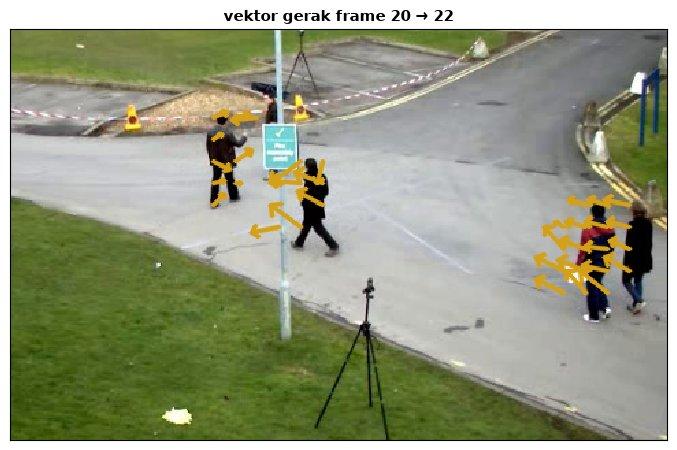

In [12]:
def block_matching(a, b, blok=16, cari=12, ambang=8, yakin=0.35):
    # Vektor gerak untuk semua kotak yang berubah. Hasil: list (x_tengah, y_tengah, dx, dy).
    ga = cv2.cvtColor(a, cv2.COLOR_BGR2GRAY).astype(np.float32)
    gb = cv2.cvtColor(b, cv2.COLOR_BGR2GRAY).astype(np.float32)
    vektor = []
    for y in range(cari, ga.shape[0] - blok - cari, blok):
        for x in range(cari, ga.shape[1] - blok - cari, blok):
            if np.abs(ga[y:y + blok, x:x + blok] - gb[y:y + blok, x:x + blok]).mean() < ambang:
                continue                              # kotak tidak berubah -> lewati
            dx, dy, beda = cari_blok(ga, gb, x, y, blok, cari)
            diam = beda[cari, cari]                   # skor kalau dianggap tidak bergerak
            if (dx or dy) and max(abs(dx), abs(dy)) < cari and beda.min() < yakin * diam:
                vektor.append((x + blok // 2, y + blok // 2, dx, dy))
    return vektor


vektor = block_matching(jalan[T0], jalan[T0 + K])
img = jalan[T0].copy()
for x, y, dx, dy in vektor:
    cv2.arrowedLine(img, (x, y), (x + 2 * dx, y + 2 * dy), (23, 160, 212), 2, cv2.LINE_AA, tipLength=0.3)
print(f"{len(vektor)} kotak bergerak dengan yakin")
jajar([(img[100:400, 160:640], f"vektor gerak frame {T0} → {T0 + K}")], ukuran=7)

Panah-panah inilah yang disimpan di **P-frame**. Kotak di daerah polos (aspal, rumput) tidak diberi panah:
daerah tanpa pola **tidak bisa** diketahui geraknya, karena cocok dengan banyak tempat.

### 5.2 Optical flow Lucas-Kanade: ikuti titik-titik

**Optical flow** mencari gerak **per titik**. Metode Lucas-Kanade memakai dua anggapan sederhana:
1. **Warnanya setia:** titik yang cokelat tetap cokelat di frame berikutnya, hanya pindah tempat.
2. **Tetangga kompak:** titik-titik di jendela kecil di sekitarnya (misalnya 15×15) bergerak bersama.

Titik yang paling enak diikuti adalah **sudut** (pojok jendela, ujung rambu). Daerah polos dan tepi lurus menyembunyikan gerak
(**masalah lubang kunci**). OpenCV memilih titik sudut dengan `cv2.goodFeaturesToTrack`.

300 titik sudut, 300 masih terlacak, 20 bergerak mulus, 34 melompat-lompat


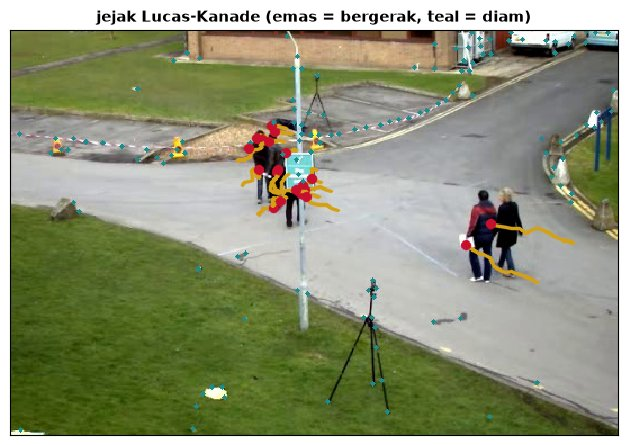

In [13]:
def jejak_lk(frames, mulai=20, n=15, jendela=15):
    # Pilih titik sudut di frame 'mulai', ikuti n frame dengan Lucas-Kanade. Hasil: (jejak, hidup)
    prev = cv2.cvtColor(frames[mulai], cv2.COLOR_BGR2GRAY)
    p = cv2.goodFeaturesToTrack(prev, maxCorners=300, qualityLevel=0.01, minDistance=7)
    lk = dict(winSize=(jendela, jendela), maxLevel=2,
              criteria=(cv2.TERM_CRITERIA_EPS | cv2.TERM_CRITERIA_COUNT, 10, 0.03))
    jejak, hidup = [p.reshape(-1, 2).copy()], np.ones(len(p), bool)
    for f in frames[mulai + 1:mulai + 1 + n]:
        g = cv2.cvtColor(f, cv2.COLOR_BGR2GRAY)
        p, status, _ = cv2.calcOpticalFlowPyrLK(prev, g, p, None, **lk)   # inti Lucas-Kanade
        hidup &= status.ravel() == 1
        jejak.append(p.reshape(-1, 2).copy())
        prev = g
    return np.stack(jejak), hidup


def gambar_jejak(frames, jejak, hidup, mulai=20):
    img = frames[mulai + len(jejak) - 1].copy()
    loncat = np.linalg.norm(np.diff(jejak, axis=0), axis=2).max(0)
    gerak = np.linalg.norm(jejak[-1] - jejak[0], axis=1)
    mulus = hidup & (loncat < 10)
    for j in range(jejak.shape[1]):
        if not mulus[j]:
            continue
        if gerak[j] > 6:
            cv2.polylines(img, [jejak[:, j].astype(np.int32)], False, (23, 160, 212), 2, cv2.LINE_AA)
            cv2.circle(img, tuple(jejak[-1, j].astype(int)), 4, (46, 16, 200), -1, cv2.LINE_AA)
        else:
            cv2.circle(img, tuple(jejak[-1, j].astype(int)), 2, (140, 140, 30), -1)
    return img, int((hidup & (loncat >= 10)).sum()), int((mulus & (gerak > 6)).sum())


jejak, hidup = jejak_lk(jalan)
img, n_loncat, n_gerak = gambar_jejak(jalan, jejak, hidup)
print(f"{len(hidup)} titik sudut, {hidup.sum()} masih terlacak, {n_gerak} bergerak mulus, {n_loncat} melompat-lompat")
jajar([(img[60:420, 100:640], "jejak Lucas-Kanade (emas = bergerak, teal = diam)")], ukuran=7)

🎬 **Demo Dosen — tebak dulu:** kalau jendela Lucas-Kanade diperkecil dari 15×15 menjadi 5×5, jejak makin rapi atau makin kacau?

In [14]:
# ✏️ Coba Ubah: ukuran jendela Lucas-Kanade
for jendela in [5, 15, 31]:
    jj, hh = jejak_lk(jalan, jendela=jendela)
    _, n_loncat, n_gerak = gambar_jejak(jalan, jj, hh)
    print(f"jendela {jendela:2d}x{jendela:<2d}: {hh.sum():3d} titik terlacak, {n_gerak:2d} bergerak mulus, {n_loncat:2d} melompat-lompat")

jendela  5x5 : 298 titik terlacak, 11 bergerak mulus, 41 melompat-lompat
jendela 15x15: 300 titik terlacak, 20 bergerak mulus, 34 melompat-lompat
jendela 31x31: 300 titik terlacak, 28 bergerak mulus, 24 melompat-lompat


### 5.3 Optical flow untuk semua piksel (Farnebäck)

Lucas-Kanade mengikuti titik pilihan. Metode **Farnebäck** memberi panah untuk **setiap piksel** (*dense optical flow*).
Agar mudah dilihat, panah diubah menjadi warna: **warna = arah** gerak, **terang = cepat**, hitam = diam.

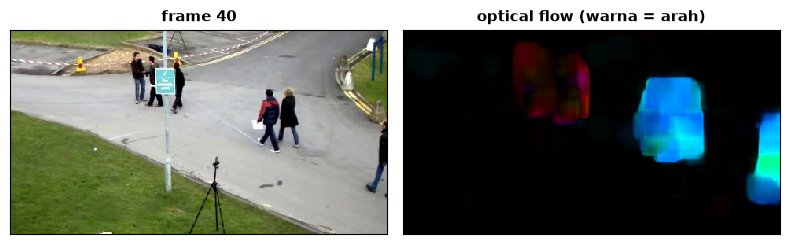

In [15]:
def flow_farneback(a, b):
    ga, gb = cv2.cvtColor(a, cv2.COLOR_BGR2GRAY), cv2.cvtColor(b, cv2.COLOR_BGR2GRAY)
    return cv2.calcOpticalFlowFarneback(ga, gb, None, 0.5, 4, 25, 3, 7, 1.5, 0)


def warna_flow(flow):
    # arah gerak -> warna (hue), kecepatan -> kecerahan
    mag, ang = cv2.cartToPolar(flow[..., 0], flow[..., 1])
    hsv = np.zeros(flow.shape[:2] + (3,), np.uint8)
    hsv[..., 0] = ang * 180 / np.pi / 2
    hsv[..., 1] = 255
    skala = np.percentile(mag[mag > 0.5], 80) if (mag > 0.5).any() else 1.0
    hsv[..., 2] = np.clip(mag * 255 / max(skala, 1e-3), 0, 255).astype(np.uint8)
    return cv2.cvtColor(hsv, cv2.COLOR_HSV2BGR)


flow = flow_farneback(jalan[40], jalan[42])
jajar([(jalan[40][120:380, 160:640], "frame 40"), (warna_flow(flow)[120:380, 160:640], "optical flow (warna = arah)")])

### 5.4 Bonus: stabilisasi video

Optical flow juga bisa **meluruskan video goyang**. Kita buat video pejalan kaki sengaja goyang, lalu:
1. lacak titik-titik latar dengan Lucas-Kanade, 2. hitung geseran kamera antar-frame,
3. haluskan lintasannya (rata-rata bergerak), 4. geser tiap frame untuk menutup selisihnya.

galat tebakan lintasan kamera: 0.20 piksel


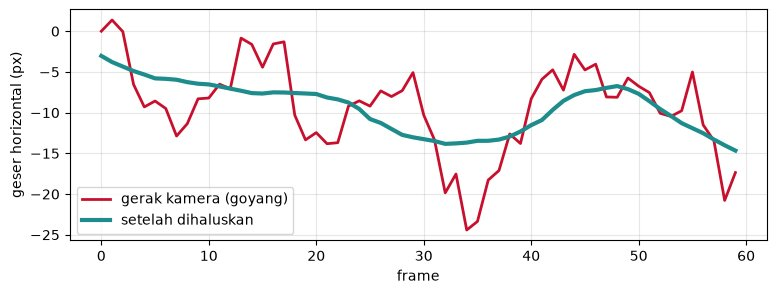

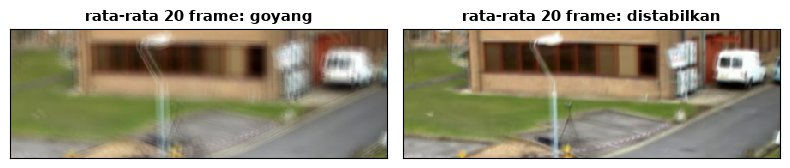

In [16]:
rng = np.random.default_rng(3)
N_ST = 60
goyang = np.cumsum(rng.normal(0, 3.2, (N_ST, 2)), axis=0)
goyang -= goyang.mean(0)
h, w = jalan[0].shape[:2]
geser = lambda img, dx, dy: cv2.warpAffine(img, np.float32([[1, 0, dx], [0, 1, dy]]), (w, h),
                                           borderMode=cv2.BORDER_REFLECT)
video_goyang = [geser(jalan[i], *goyang[i]) for i in range(N_ST)]

# 1-2. estimasi gerak kamera antar-frame
lintasan = [np.zeros(2)]
prev = cv2.cvtColor(video_goyang[0], cv2.COLOR_BGR2GRAY)
for f in video_goyang[1:]:
    g = cv2.cvtColor(f, cv2.COLOR_BGR2GRAY)
    p0 = cv2.goodFeaturesToTrack(prev, 200, 0.01, 20)
    p1, st, _ = cv2.calcOpticalFlowPyrLK(prev, g, p0, None)
    ok = st.ravel() == 1
    M, _ = cv2.estimateAffinePartial2D(p0[ok], p1[ok])    # geseran (dan sedikit putaran) kamera
    lintasan.append(lintasan[-1] + M[:2, 2])
    prev = g
lintasan = np.array(lintasan)

# 3. haluskan dengan rata-rata bergerak  ✏️ Coba Ubah: K_HALUS (makin besar makin halus)
K_HALUS = 15
pad = np.pad(lintasan, ((K_HALUS // 2, K_HALUS // 2), (0, 0)), mode="edge")
halus = np.stack([np.convolve(pad[:, c], np.ones(K_HALUS) / K_HALUS, mode="valid") for c in range(2)], 1)

# 4. geser tiap frame
video_stabil = [geser(f, *(halus[i] - lintasan[i])) for i, f in enumerate(video_goyang)]

print(f"galat tebakan lintasan kamera: {np.abs(lintasan - (goyang - goyang[0])).mean():.2f} piksel")
plt.figure(figsize=(9, 3))
plt.plot(lintasan[:, 0], color="#C8102E", lw=2, label="gerak kamera (goyang)")
plt.plot(halus[:, 0], color="#1E8C8C", lw=3, label="setelah dihaluskan")
plt.xlabel("frame"); plt.ylabel("geser horizontal (px)"); plt.legend(); plt.grid(alpha=0.3); plt.show()

rata = lambda vid: np.mean(np.stack(vid[10:30]).astype(np.float32), 0).astype(np.uint8)
jajar([(rata(video_goyang)[20:170, 180:620], "rata-rata 20 frame: goyang"),
       (rata(video_stabil)[20:170, 180:620], "rata-rata 20 frame: distabilkan")])

## 6. Green Screen (Chroma Key)

Resepnya hanya 4 langkah, dan semua bahannya sudah Anda pelajari:
1. **Rekam** objek di depan layar hijau.
2. Ubah ke **HSV**, lalu tandai piksel hijau dengan `cv2.inRange` (Modul 06).
3. **Balik** mask (yang bukan hijau = objek), rapikan dengan **morfologi** (Modul 09).
4. **Tempel:** piksel objek diambil dari rekaman, sisanya dari latar baru.

Fungsi `mask_objek` sudah kita definisikan di Bagian 2.1. Sekarang kita pakai sungguhan.

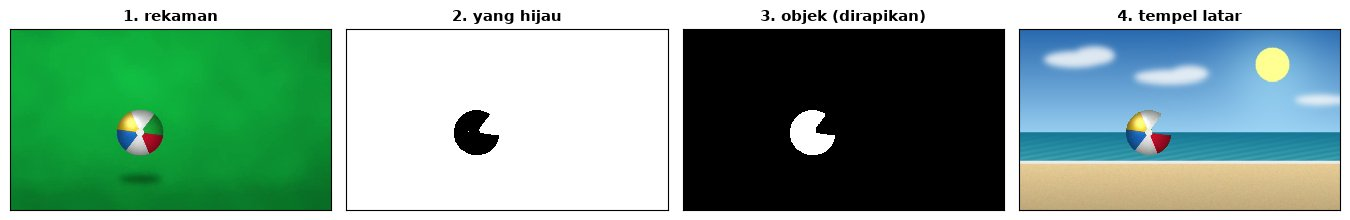

In [17]:
latar = cv2.imread(cari_file("image/latar_pantai.jpg"))
latar = cv2.resize(latar, (bola[0].shape[1], bola[0].shape[0]))   # latar harus seukuran frame


def chroma_key(frame, latar, **kw):
    m = mask_objek(frame, **kw)
    return np.where(m[..., None] > 0, frame, latar)   # objek dari rekaman, sisanya dari latar


f = bola[45]
hsv = cv2.cvtColor(f, cv2.COLOR_BGR2HSV)
hijau = cv2.inRange(hsv, np.array(HIJAU_BAWAH), np.array(HIJAU_ATAS))
jajar([(f, "1. rekaman"), (hijau, "2. yang hijau"), (mask_objek(f), "3. objek (dirapikan)"),
       (chroma_key(f, latar), "4. tempel latar")], ukuran=3.4)

Bagaimana memilih angka `HIJAU_BAWAH` dan `HIJAU_ATAS`? Lihat **histogram Hue** satu frame.
Di OpenCV, Hue hanya **0–179** (bukan 0–359); hijau murni ada di sekitar 60.

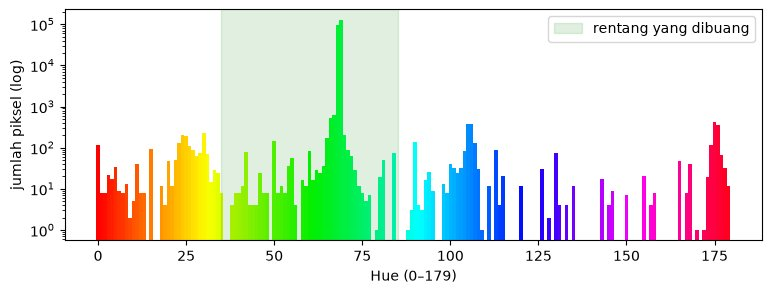

Hue layar hijau (median): 69


In [18]:
hist = np.bincount(hsv[..., 0].ravel(), minlength=180)
plt.figure(figsize=(9, 3))
plt.bar(np.arange(180), hist, width=1.0, color=[plt.cm.hsv(i / 180) for i in range(180)])
plt.axvspan(HIJAU_BAWAH[0], HIJAU_ATAS[0], color="green", alpha=0.12, label="rentang yang dibuang")
plt.yscale("log"); plt.xlabel("Hue (0–179)"); plt.ylabel("jumlah piksel (log)"); plt.legend(); plt.show()
print("Hue layar hijau (median):", int(np.median(hsv[..., 0][hijau > 0])))

🎬 **Demo Dosen — tebak dulu:** kalau batas bawah **V** (kecerahan) dinaikkan dari 60 menjadi 150, bagian kain mana yang **tidak** terhapus?

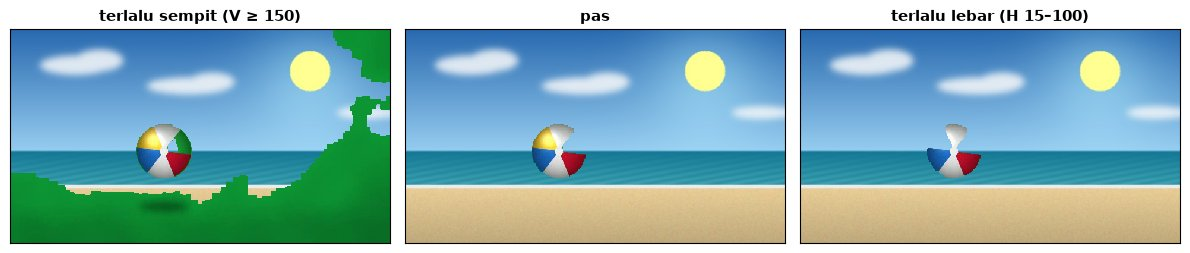

In [19]:
# ✏️ Coba Ubah: rentang (H, S, V) bawah & atas
PENGATURAN = [((35, 60, 150), (85, 255, 255), "terlalu sempit (V ≥ 150)"),
              ((35, 60, 60),  (85, 255, 255), "pas"),
              ((15, 40, 40),  (100, 255, 255), "terlalu lebar (H 15–100)")]
jajar([(chroma_key(f, latar, bawah=lo, atas=hi), judul) for lo, hi, judul in PENGATURAN], ukuran=4)

- **Terlalu sempit:** sisi kanan dan lantai kain yang kurang cahaya punya V < 150, jadi **tidak terhapus**.
- **Terlalu lebar:** segmen **kuning** bola (Hue ≈ 23) ikut dianggap layar → bola bolong.
- **Pas:** latar bersih… tapi perhatikan **segmen hijau** bola! Warnanya masuk rentang hijau, jadi ikut hilang.
  Komputer tidak tahu mana "kain" dan mana "bola"; ia hanya melihat warna. Pelajarannya: **jangan pakai baju hijau** di depan green screen.

Sekarang terapkan ke **seluruh 120 frame**:

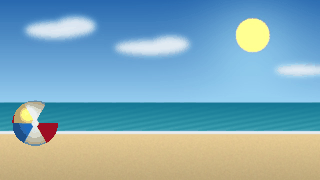

GIF disimpan: output/bola_pantai.gif (686 KB)


In [20]:
komposit = [chroma_key(fr, latar) for fr in bola]
tampil_gif(komposit, "bola_pantai.gif", fps=fps_bola)

## 7. Melacak Objek (Tracking)

**Deteksi** = mencari objek dari nol di setiap frame (akurat tapi lambat).
**Pelacakan** = tunjuk objeknya **sekali**, lalu tracker mengikutinya frame demi frame (cepat, tapi bisa tersesat).

Cara pakai tracker OpenCV selalu 3 langkah:
1. buat tracker (`cv2.TrackerCSRT_create()`), 2. `init(frame_pertama, kotak_awal)`, 3. `update(frame)` di setiap frame.

Kotak awal (ROI) ditulis sebagai `(x, y, lebar, tinggi)`.

In [21]:
def buat_tracker(nama="CSRT"):
    # CSRT & KCF butuh opencv-contrib-python; kalau tidak ada, pakai MIL sebagai cadangan
    pembuat = {"CSRT": "TrackerCSRT_create", "KCF": "TrackerKCF_create", "MIL": "TrackerMIL_create"}
    fungsi = getattr(cv2, pembuat[nama], None)
    if fungsi is None:
        print(f"⚠️ {nama} tidak tersedia (pasang opencv-contrib-python). Memakai MIL sebagai cadangan.")
        fungsi = cv2.TrackerMIL_create
    return fungsi()


def lacak(frames, roi, nama="CSRT"):
    # Jalankan tracker di semua frame. Hasil: list kotak (None kalau hilang) & kecepatan (fps).
    tracker = buat_tracker(nama)
    tracker.init(frames[0], roi)
    kotak = [tuple(roi)]
    t0 = time.perf_counter()
    for f in frames[1:]:
        ok, b = tracker.update(f)
        kotak.append(tuple(int(v) for v in b) if ok else None)
    return kotak, (len(frames) - 1) / (time.perf_counter() - t0)


def gambar_kotak(img, b, warna, label=None):
    if b is None:
        return
    x, y, w, h = b
    cv2.rectangle(img, (x, y), (x + w, y + h), warna, 3, cv2.LINE_AA)
    if label:
        tulis(img, label, (x, max(18, y - 8)), 0.6, warna)

### 7.1 Memilih kotak awal

Di notebook (dan Colab) kita menulis **koordinat** langsung. Kotak `(532, 200, 39, 72)` adalah pria bermantel gelap di kanan frame 0.

Kalau Anda menjalankan notebook **di laptop sendiri**, Anda juga bisa memilih kotak dengan mouse memakai `cv2.selectROI`
(ubah `PILIH_SENDIRI = True`). Seret kotak, lalu tekan **ENTER** atau **SPASI**.

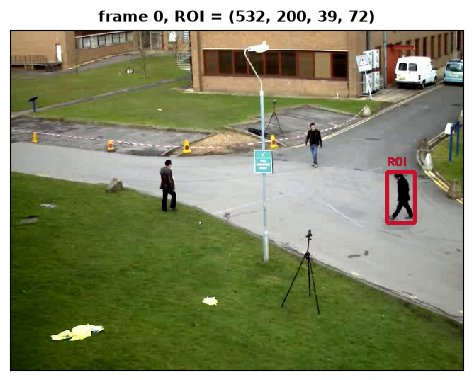

In [22]:
ROI_ORANG = (532, 200, 39, 72)   # (x, y, lebar, tinggi)

PILIH_SENDIRI = False            # ✏️ Coba Ubah: True di laptop sendiri (butuh jendela GUI)
if PILIH_SENDIRI:
    ROI_ORANG = tuple(int(v) for v in cv2.selectROI("Pilih objek lalu ENTER", jalan[0], showCrosshair=True))
    cv2.destroyAllWindows()

img = jalan[0].copy()
gambar_kotak(img, ROI_ORANG, (46, 16, 200), "ROI")
jajar([(img, f"frame 0, ROI = {ROI_ORANG}")], ukuran=6)

### 7.2 CSRT vs KCF

- **CSRT**: lebih teliti, tahan terhadap perubahan bentuk, tapi lebih lambat.
- **KCF**: sangat cepat, tapi "jujur": kalau rupa objek berubah, ia menyatakan **hilang**.

CSRT:    91 fps | hilang di 0/150 frame | pertama hilang: frame None


KCF:  1532 fps | hilang di 146/150 frame | pertama hilang: frame 3


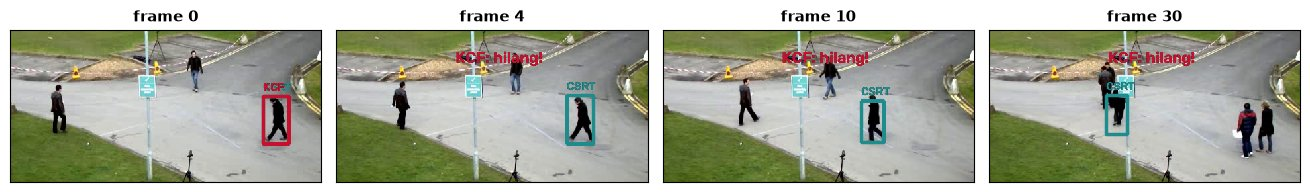

In [23]:
hasil = {}
for nama in ["CSRT", "KCF"]:
    kotak, kecepatan = lacak(jalan, ROI_ORANG, nama)
    hasil[nama] = kotak
    hilang = sum(b is None for b in kotak)
    pertama = next((i for i, b in enumerate(kotak) if b is None), None)
    print(f"{nama}: {kecepatan:5.0f} fps | hilang di {hilang}/{len(kotak)} frame | pertama hilang: frame {pertama}")

daftar = []
for i in [0, 4, 10, 30]:
    im = jalan[i].copy()
    gambar_kotak(im, hasil["CSRT"][i], (140, 140, 30), "CSRT")
    if hasil["KCF"][i] is None:
        tulis(im, "KCF: hilang!", (330, 150), 0.8, (46, 16, 200))
    else:
        gambar_kotak(im, hasil["KCF"][i], (46, 16, 200), "KCF")
    daftar.append((im[100:330, 150:620], f"frame {i}"))
jajar(daftar, ukuran=3.3)

In [24]:
# Kecepatan yang adil: objek kaku digeser 3 piksel per frame (keduanya berhasil)
geser_kaku = [np.roll(jalan[0], -3 * i, axis=1) for i in range(60)]
for nama in ["CSRT", "KCF"]:
    kotak, kecepatan = lacak(geser_kaku, (300, 150, 60, 70), nama)
    print(f"{nama} pada objek kaku: {kecepatan:5.0f} fps, hilang {sum(b is None for b in kotak)}/60")

CSRT pada objek kaku:    86 fps, hilang 0/60
KCF pada objek kaku:   383 fps, hilang 0/60


🎬 **Demo Dosen — tebak dulu:** kalau kotak awal dibuat **jauh lebih besar** dari orangnya (ikut memuat banyak aspal), apa yang terjadi?

frame   0: selisih pusat kotak besar vs kotak pas =   1.8 px
frame  10: selisih pusat kotak besar vs kotak pas =   6.6 px
frame  20: selisih pusat kotak besar vs kotak pas =   5.4 px
frame  30: selisih pusat kotak besar vs kotak pas =  37.0 px
frame  60: selisih pusat kotak besar vs kotak pas =  11.0 px


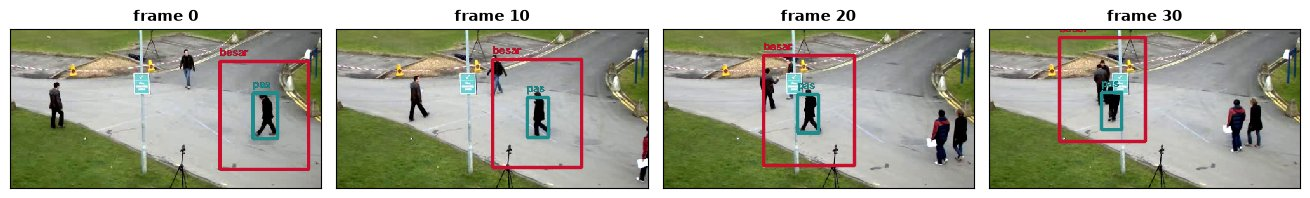

In [25]:
# ✏️ Coba Ubah: ukuran kotak awal
ROI_BESAR = (480, 150, 140, 170)
kotak_besar, _ = lacak(jalan, ROI_BESAR, "CSRT")

def pusat(b):
    return None if b is None else np.array([b[0] + b[2] / 2, b[1] + b[3] / 2])

for i in [0, 10, 20, 30, 60]:
    a, b = pusat(hasil["CSRT"][i]), pusat(kotak_besar[i])
    beda = "hilang" if (a is None or b is None) else f"{np.linalg.norm(a - b):5.1f} px"
    print(f"frame {i:3d}: selisih pusat kotak besar vs kotak pas = {beda}")

daftar = []
for i in [0, 10, 20, 30]:
    im = jalan[i].copy()
    gambar_kotak(im, hasil["CSRT"][i], (140, 140, 30), "pas")
    gambar_kotak(im, kotak_besar[i], (46, 16, 200), "besar")
    daftar.append((im[100:350, 150:640], f"frame {i}"))
jajar(daftar, ukuran=3.3)

### 7.3 Saat tracker tersesat: oklusi

Apa yang terjadi kalau objek **tertutup** sesuatu? Kita tambahkan "tiang" abu-abu buatan di jalur pria bermantel.

frame  4: selisih dengan lintasan tanpa tiang =     5 px
frame  8: selisih dengan lintasan tanpa tiang =    62 px
frame 16: selisih dengan lintasan tanpa tiang =   133 px
frame 30: selisih dengan lintasan tanpa tiang =   198 px


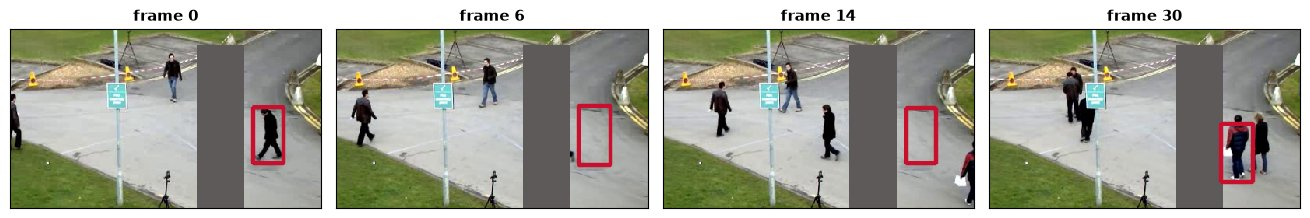

In [26]:
TIANG = (460, 120, 60, 210)   # ✏️ Coba Ubah: posisi & lebar tiang
jalan_tiang = []
for fr in jalan:
    g = fr.copy()
    cv2.rectangle(g, TIANG[:2], (TIANG[0] + TIANG[2], TIANG[1] + TIANG[3]), (90, 90, 95), -1)
    jalan_tiang.append(g)

kotak_tiang, _ = lacak(jalan_tiang, ROI_ORANG, "CSRT")
for i in [4, 8, 16, 30]:
    a, b = pusat(hasil["CSRT"][i]), pusat(kotak_tiang[i])
    print(f"frame {i:2d}: selisih dengan lintasan tanpa tiang = {np.linalg.norm(a - b):5.0f} px")

daftar = []
for i in [0, 6, 14, 30]:
    im = jalan_tiang[i].copy()
    gambar_kotak(im, kotak_tiang[i], (46, 16, 200))
    daftar.append((im[100:330, 220:620], f"frame {i}"))
jajar(daftar, ukuran=3.3)

Pria lewat di belakang tiang dan kotak **tertinggal** di tempat ia menghilang. Tracker hanya mengingat **rupa**, bukan **siapa**.
Solusi praktis di aplikasi nyata: jalankan **deteksi ulang** secara berkala, atau saat tracker mulai ragu.

## 8. Studi Kasus: Green Screen + Tracking

Kita gabungkan Bagian 6 dan 7:
1. Ambil **kotak awal otomatis** dari mask frame 0 (tidak perlu klik).
2. Lacak bola dengan CSRT **di rekaman asli** (latar hijau polos = mudah dilacak).
3. Lakukan chroma key ke pantai.
4. Gambar kotak + jejak lintasan di atas hasil komposit.

> 💡 Kenapa melacak di rekaman asli, bukan di hasil komposit? Di komposit, segmen hijau bola sudah berubah menjadi langit/laut,
> sehingga "rupa" bola terus berganti saat berputar. Prinsipnya: **ukur di data paling bersih, tampilkan di mana saja.**

kotak awal otomatis: (20, 197, 100, 99)


CSRT: 87 fps, hilang 0/120 frame


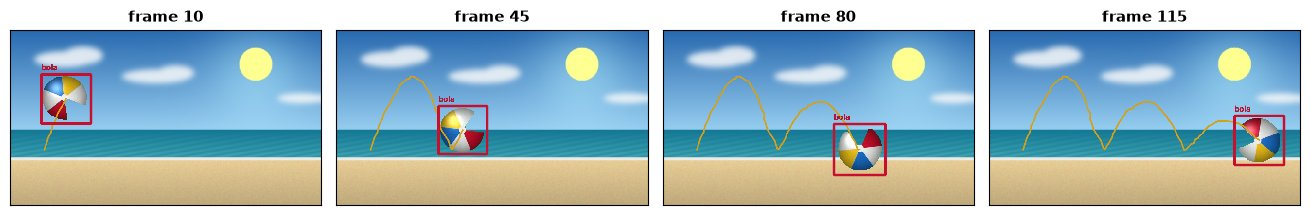

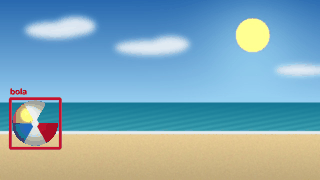

GIF disimpan: output/studi_kasus.gif (763 KB)


In [27]:
x, y, w, h = cv2.boundingRect(cv2.findNonZero(mask_objek(bola[0])))
ROI_BOLA = (x - 4, y - 4, w + 8, h + 8)
print("kotak awal otomatis:", ROI_BOLA)

kotak_bola, kecepatan = lacak(bola, ROI_BOLA, "CSRT")   # lacak di rekaman ASLI
print(f"CSRT: {kecepatan:.0f} fps, hilang {sum(b is None for b in kotak_bola)}/{len(kotak_bola)} frame")

hasil_akhir, jejak_pusat = [], []
for fr, b in zip(komposit, kotak_bola):
    im = fr.copy()
    if b is not None:
        jejak_pusat.append((b[0] + b[2] // 2, b[1] + b[3] // 2))
    if len(jejak_pusat) > 1:
        cv2.polylines(im, [np.array(jejak_pusat, np.int32)], False, (23, 160, 212), 2, cv2.LINE_AA)
    gambar_kotak(im, b, (46, 16, 200), "bola")
    hasil_akhir.append(im)

jajar([(hasil_akhir[i], f"frame {i}") for i in [10, 45, 80, 115]], ukuran=3.3)
tampil_gif(hasil_akhir, "studi_kasus.gif", fps=fps_bola)

In [28]:
# Simpan juga sebagai MP4 (bisa diputar di laptop Anda)
h, w = hasil_akhir[0].shape[:2]
out = cv2.VideoWriter("output/studi_kasus.mp4", cv2.VideoWriter_fourcc(*"mp4v"), fps_bola, (w, h))
for im in hasil_akhir:
    out.write(im)
out.release()
print("tersimpan: output/studi_kasus.mp4", os.path.getsize("output/studi_kasus.mp4") // 1024, "KB")

tersimpan: output/studi_kasus.mp4 553 KB


## 9. Finale: Hidung Badut 🔴

Semua bahan sudah terkumpul. Script **`10_hidung_badut.py`** (di folder yang sama dengan notebook ini) membuat
bulatan merah yang **menempel di hidung Anda** saat menatap webcam:

| Langkah | Apa yang dilakukan | Materi |
|---|---|---|
| 1 | `cv2.VideoCapture(0)` membaca webcam frame demi frame | Bagian 3 |
| 2 | Cari wajah **sekali** dengan detektor YuNet, yang langsung memberi titik ujung hidung | Pertemuan 11 |
| 3 | Ambil ±30 titik sudut di sekitar hidung, lalu ikuti dengan **Lucas-Kanade** | Bagian 5.2 |
| 4 | **Median** posisi titik = pusat hidung → gambar bulatan merah | — |
| ↺ | Kalau titik tersisa < 5 (misalnya wajah ditutup tangan), kembali ke langkah 2 | Bagian 7.3 |

### Cara menjalankan (di laptop sendiri, bukan Colab)
```bash
cd notebook_handson
python 10_hidung_badut.py              # pakai webcam
python 10_hidung_badut.py video.mp4    # atau pakai file video berisi wajah
```
Tombol: **q** keluar · **r** cari wajah lagi · **s** pilih hidung sendiri dengan mouse.

Saat pertama kali dijalankan, script mengunduh model detektor wajah YuNet (±230 KB) ke folder `model/`.

### ✏️ Coba ubah di script
- Warna hidung: `(40, 40, 230)` di `gambar_hidung` → coba `(230, 120, 40)` untuk hidung biru.
- Ukuran hidung: angka `0.6` di `mulai_dari_kotak`.
- Hapus `cv2.flip(frame, 1)` dan rasakan bedanya.
- Tantangan: ganti bulatan merah dengan **kacamata** (dua lingkaran di atas hidung)!

Sel di bawah hanya menampilkan isi script agar mudah dibaca.

In [29]:
with open(cari_file("10_hidung_badut.py"), encoding="utf-8") as fh:
    print(fh.read())

"""
10_hidung_badut.py — Hidung badut yang ikut bergerak bersama hidung Anda (webcam live)
IF25-40305 Sistem Teknologi Multimedia · Modul 10 · ITERA

Cara menjalankan (di laptop sendiri, BUKAN di Colab, karena butuh webcam & jendela):
    python 10_hidung_badut.py              # pakai webcam
    python 10_hidung_badut.py video.mp4    # atau pakai file video

Tombol:  q = keluar   r = cari wajah lagi   s = pilih hidung sendiri dengan mouse

Cara kerjanya (4 langkah):
  1. Ambil gambar dari webcam, satu frame demi satu frame.
  2. Cari wajah SEKALI saja (detektor YuNet langsung memberi titik ujung hidung).
  3. Ikuti titik-titik di sekitar hidung dengan optical flow Lucas-Kanade.
  4. Gambar bulatan merah (hidung badut) di tengah titik-titik itu.
  Kalau titiknya hilang (misalnya wajah ditutup tangan), kembali ke langkah 2.
"""
import os
import sys
import urllib.request
import cv2
import numpy as np

# --- 1. Sumber video: angka 0 = webcam bawaan laptop -------------------------
sumber =

## 10. Rangkuman

1. **Video** = tumpukan frame. Jumlah frame = **FPS × durasi**. Resolusi = kerincian tiap frame.
2. Baca video dengan `cv2.VideoCapture` (angka `0` = webcam). Simpan dengan `cv2.VideoWriter`, ukurannya harus **sama persis** dengan frame.
3. Frame berurutan **hampir sama** (98% piksel), jadi **codec** hanya menyimpan perubahan: I-frame (foto lengkap) + P/B-frame (catatan gerak).
4. **Block matching**: cari kotak paling mirip di sekitar posisi lama → vektor gerak.
5. **Optical flow Lucas-Kanade** mengikuti titik **sudut**. Daerah polos dan tepi lurus menyembunyikan gerak (masalah lubang kunci).
6. **Chroma key** = HSV + `inRange` + morfologi + tempel. Jangan pakai baju hijau!
7. **Tracker**: tunjuk sekali, ikuti terus. CSRT teliti, KCF cepat. Oklusi membuat tracker tersesat → deteksi ulang.

### 🧭 Lembar Contekan
| Tujuan | Kode |
|---|---|
| Buka video / webcam | `cap = cv2.VideoCapture("file.mp4")` / `cv2.VideoCapture(0)` |
| Ambil 1 frame | `ok, frame = cap.read()` |
| Info video | `cap.get(cv2.CAP_PROP_FPS)`, `cv2.CAP_PROP_FRAME_COUNT` |
| Simpan video | `cv2.VideoWriter(nama, cv2.VideoWriter_fourcc(*"mp4v"), fps, (lebar, tinggi))` |
| Selisih frame | `cv2.absdiff(abu_a, abu_b)` |
| Cari kotak mirip | `cv2.matchTemplate(jendela, kotak, cv2.TM_SQDIFF)` |
| Titik sudut | `cv2.goodFeaturesToTrack(abu, 300, 0.01, 7)` |
| Lucas-Kanade | `cv2.calcOpticalFlowPyrLK(abu_lama, abu, titik, None)` |
| Flow semua piksel | `cv2.calcOpticalFlowFarneback(a, b, None, 0.5, 4, 25, 3, 7, 1.5, 0)` |
| Mask hijau | `cv2.inRange(hsv, (35, 60, 60), (85, 255, 255))` |
| Tracker | `t = cv2.TrackerCSRT_create(); t.init(f0, roi); ok, kotak = t.update(f)` |

> 🔜 **Pertemuan berikutnya:** Deteksi wajah, landmark & kode digital (QR code, barcode).